# 2. VLA architecture, evaluation, and interpretability

This notebook addresses take-home Steps **2–4**: reproduce the official baseline, evaluate a controlled multi-camera architecture change, and inspect language-to-image attention with matched top-attention/random masking. Additional diagnostics are clearly labeled as supplementary. All performance tables load saved experiment outputs rather than hardcoded values.

**Prerequisites:** run the documented training/evaluation scripts and keep `results/` available. The attention experiments require the **trained** `checkpoints/baseline.pt`; an untrained fallback is intentionally not used.

## 1. Establish the official baseline

From the repository root, run the baseline without changing its configuration:

```bash
uv run python scripts/run_baseline.py
```

The run writes metrics to `results/metrics.json` and the trained model to `checkpoints/baseline.pt`. Explain what each reported metric measures and note any limitations before comparing it with your architecture change.

In [15]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

ROOT = next(
    (
        p
        for p in (Path.cwd().resolve(), *Path.cwd().resolve().parents)
        if (p / "results").is_dir() and (p / "src").is_dir()
    ),
    None,
)
if ROOT is None:
    raise FileNotFoundError("Run from the repository root or its notebooks/ directory")
RESULTS = ROOT / "results"


def json_result(relative):
    path = RESULTS / relative
    if not path.is_file():
        raise FileNotFoundError(f"Missing {path}; run the corresponding experiment")
    return json.loads(path.read_text(encoding="utf-8"))


def csv_result(relative):
    path = RESULTS / relative
    if not path.is_file():
        raise FileNotFoundError(f"Missing {path}; run the corresponding experiment")
    return pd.read_csv(path)


def col(frame, *names):
    return next((name for name in names if name in frame.columns), None) or (_ for _ in ()).throw(
        KeyError(f"Expected one of {names}; found {frame.columns.tolist()}")
    )


baseline_metrics = json_result("baseline/metrics.json")
required = ["parameters", "elapsed_seconds", "validation"]
assert all(k in baseline_metrics for k in required), (
    f"Baseline metrics missing required keys: {required}"
)
assert all(k in baseline_metrics["validation"] for k in ("mse", "endpoint_error", "smoothness"))

baseline_table = pd.DataFrame(
    [
        {
            "validation_mse": baseline_metrics["validation"]["mse"],
            "endpoint_error": baseline_metrics["validation"]["endpoint_error"],
            "smoothness": baseline_metrics["validation"]["smoothness"],
            "parameters": baseline_metrics["parameters"],
            "training_wall_seconds": baseline_metrics["elapsed_seconds"],
        }
    ]
)
display(baseline_table.round(6))
print("Baseline source:", RESULTS / "baseline/metrics.json")

,validation_mse,endpoint_error,smoothness,parameters,training_wall_seconds
0,0.03223,0.923881,0.104621,184391,378.308607


Baseline source: C:\Users\parin\Documents\projects\ml-project-aliriahi90\results\baseline\metrics.json


### Metric definitions and limitations

- **Action MSE:** mean squared difference between predicted and labeled action elements over the 8 × 7 chunk. A low value does not establish successful manipulation, and a single high-error channel can dominate the average.
- **Endpoint error:** final-step position/action discrepancy as defined by the official evaluator; use that implementation rather than a different custom XYZ proxy.
- **Smoothness:** mean temporal change between successive predicted actions, according to the evaluator. Lower is not automatically better: real actions, including gripper transitions, can be discontinuous.
- **Trainable parameters:** capacity proxy, not a direct runtime or memory measure.
- **Training wall time:** elapsed duration of the recorded training run; depends on device and environment.
- **Evaluation throughput:** measured below on the trained baseline and labeled explicitly as a forward-pass benchmark, not an official end-to-end evaluator measurement.

All architecture runs should use the same seed, step budget, training data, and validation split. Deployment labels must not be used for model selection.

In [16]:
import time

import torch
from torch.utils.data import DataLoader

from ml_project.checkpoint import load_model_checkpoint
from ml_project.data import make_default_datasets
from ml_project.interpretability import attention_heatmap, language_to_image_attention

torch.manual_seed(0)
checkpoint_path = ROOT / "checkpoints" / "baseline.pt"
if not checkpoint_path.is_file():
    raise FileNotFoundError(
        f"Trained baseline checkpoint required for attention analysis: {checkpoint_path}"
    )
analysis_model, checkpoint_metadata = load_model_checkpoint(checkpoint_path)
analysis_model.eval()
model_label = f"trained baseline ({checkpoint_path.relative_to(ROOT)})"

datasets = make_default_datasets(
    image_size=analysis_model.config.image_size,
    max_text_length=analysis_model.config.max_text_length,
    train_size=512,
    validation_size=128,
    deployment_size=128,
)
validation_loader = DataLoader(datasets["validation"], batch_size=16, shuffle=False)
batch = next(iter(DataLoader(datasets["validation"], batch_size=4, shuffle=False)))
print("Model:", model_label)
print("Parameters:", analysis_model.parameter_count())
print("Checkpoint metadata:", checkpoint_metadata)
print("Validation examples:", len(datasets["validation"]))

Model: trained baseline (checkpoints\baseline.pt)
Parameters: 184391
Checkpoint metadata: {'seed': 7, 'steps': 200, 'learning_rate': 0.0003}
Validation examples: 128


C:\Users\parin\Documents\projects\ml-project-aliriahi90\src\ml_project\model.py:135: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.norm_first was True
  self.decoder = nn.TransformerEncoder(layer, num_layers=config.num_action_layers)


In [17]:
analysis_model.eval()

with torch.no_grad():
    context, attentions, hidden_states = analysis_model.encode(
        images=batch["images"],
        image_masks=batch["image_masks"],
        input_ids=batch["input_ids"],
        attention_mask=batch["attention_mask"],
        state=batch["state"],
        return_attentions=True,
        return_hidden_states=True,
    )

print("Front image:", batch["images"]["front"].shape)
print("Wrist image:", batch["images"]["wrist"].shape)
print("Language:", batch["input_ids"].shape)
print("Robot state:", batch["state"].shape)

print("\nPatch tokens per image:", analysis_model.patches_per_image)
print("Token slices:", analysis_model.token_slices())
print("Fused context:", context.shape)

print("\nHidden states:")
for name, tensor in hidden_states.items():
    print(name, tuple(tensor.shape))

print("\nAttention matrices:")
for name, tensor in attentions.items():
    print(name, tuple(tensor.shape))

Front image: torch.Size([4, 3, 64, 64])
Wrist image: torch.Size([4, 3, 64, 64])
Language: torch.Size([4, 16])
Robot state: torch.Size([4, 7])

Patch tokens per image: 64
Token slices: {'cls': slice(0, 1, None), 'state': slice(1, 2, None), 'text': slice(2, 18, None), 'front': slice(18, 82, None), 'wrist': slice(82, 146, None)}
Fused context: torch.Size([4, 64])

Hidden states:
fusion.layer_0 (4, 146, 64)
fusion.layer_1 (4, 146, 64)
fused_tokens (4, 146, 64)

Attention matrices:
fusion.layer_0 (4, 4, 146, 146)
fusion.layer_1 (4, 4, 146, 146)


In [18]:
# This times model forward calls, not dataloading, checkpoint I/O, or evaluator postprocessing.
# Fixed sampling seed makes the stochastic action sampler reproducible.
model_device = next(analysis_model.parameters()).device


def to_device(x):
    if isinstance(x, dict):
        return {k: to_device(v) for k, v in x.items()}
    return x.to(model_device) if torch.is_tensor(x) else x


n_seen = 0
start = time.perf_counter()
with torch.inference_mode():
    for vb in validation_loader:
        vb = to_device(vb)
        prediction = analysis_model(
            images=vb["images"],
            image_masks=vb["image_masks"],
            input_ids=vb["input_ids"],
            attention_mask=vb["attention_mask"],
            state=vb["state"],
            sample_seed=7,
        )
        n_seen += prediction.actions.shape[0]
elapsed = time.perf_counter() - start
print(f"Baseline forward-pass throughput: {n_seen / elapsed:.2f} samples/s")
print(f"Baseline forward-pass elapsed time: {elapsed:.3f} s for {n_seen} validation samples")
print(
    "Caveat: wall time includes batch transfer and Python loop overhead; "
    "not official evaluator throughput."
)

Baseline forward-pass throughput: 46.54 samples/s
Baseline forward-pass elapsed time: 2.750 s for 128 validation samples
Caveat: wall time includes batch transfer and Python loop overhead; not official evaluator throughput.


In [19]:
# The measured throughput is tagged as a notebook forward-pass benchmark,
# not an official evaluator metric.
submission_metrics = dict(baseline_metrics)
submission_metrics["evaluation_forward_benchmark"] = {
    "validation_samples": int(n_seen),
    "elapsed_seconds": float(elapsed),
    "samples_per_second": float(n_seen / elapsed),
    "measurement": (
        "notebook forward-pass wall time (includes batch iteration, excludes metric computation)"
    ),
}
required_path = RESULTS / "metrics.json"
required_path.write_text(json.dumps(submission_metrics, indent=2), encoding="utf-8")
print("Saved required baseline artifact:", required_path)

Saved required baseline artifact: C:\Users\parin\Documents\projects\ml-project-aliriahi90\results\metrics.json


## 2. Controlled multi-camera architecture improvement

**Hypothesis:** simple fusion of front/wrist image tokens and language may not sufficiently select task-relevant camera patches or produce timestep-specific action representations.

**Change:** add language-guided visual cross-attention and eight learned action queries, with FiLM conditioning and training augmentations. Compare against the original TinyVLA at the same training seed and 200-step budget. The combined model has more parameters, so this is a controlled configuration comparison, **not** a parameter-matched causal ablation. The separate action-query-only and cross-attention-only runs help assess contributions.

Use the table below for validation MSE, endpoint error, smoothness, trainable parameters, and training time. Evaluation throughput for the original baseline is benchmarked above; a directly comparable improved-model throughput requires timing its checkpoint under the same procedure.

In [20]:
# Shared result loaders and repository root were defined in Section 1.
print("Repository:", ROOT)
print("Results:", RESULTS)

Repository: C:\Users\parin\Documents\projects\ml-project-aliriahi90
Results: C:\Users\parin\Documents\projects\ml-project-aliriahi90\results


Loaded: C:\Users\parin\Documents\projects\ml-project-aliriahi90\results\baseline\metrics.json
Loaded: C:\Users\parin\Documents\projects\ml-project-aliriahi90\results\robustness\baseline_both_seed7\metrics.json
Loaded: C:\Users\parin\Documents\projects\ml-project-aliriahi90\results\robustness\film_both_seed7\metrics.json
Loaded: C:\Users\parin\Documents\projects\ml-project-aliriahi90\results\action_queries_only\metrics.json
Loaded: C:\Users\parin\Documents\projects\ml-project-aliriahi90\results\language_cross_only\metrics.json
Loaded: C:\Users\parin\Documents\projects\ml-project-aliriahi90\results\cross_full\metrics.json


,model,parameters,validation_mse,endpoint_error,smoothness,train_seconds,mse_improvement_vs_baseline_pct
5,Cross-attention + action queries,243721,0.02190,0.87221,0.13031,NaN,32.04539
3,Action queries only,243721,0.02428,0.88699,0.13373,NaN,24.66385
2,FiLM + both augmentations,192839,0.02829,0.98526,0.10765,384.19836,12.21631
1,Baseline + both augmentations,184391,0.03154,0.90239,0.10338,338.79728,2.15464
0,Original TinyVLA,184391,0.03223,0.92388,0.10462,378.30861,0.00000
4,Language cross-attention only,243721,0.03629,0.95124,0.11296,NaN,-12.60769


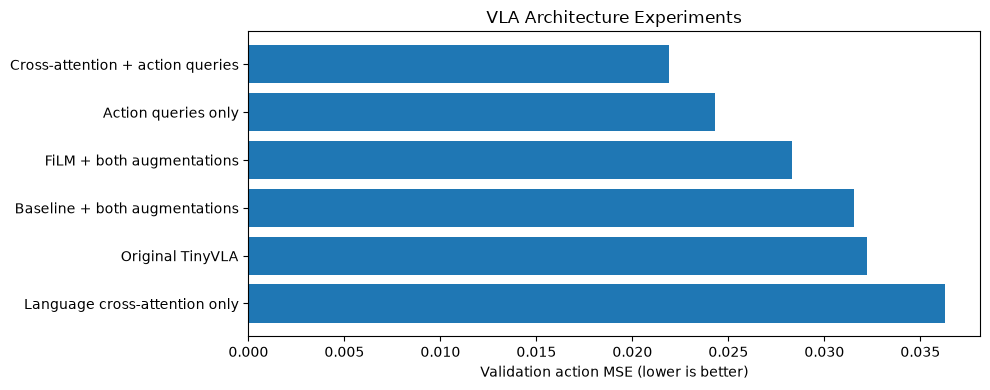

In [21]:
import json
from pathlib import Path

import pandas as pd

# Only the six selected experiments
EXPERIMENTS = {
    "Original TinyVLA": ["baseline"],
    "Baseline + both augmentations": ["robustness/baseline_both_seed7"],
    "FiLM + both augmentations": ["robustness/film_both_seed7"],
    "Action queries only": ["action_queries_only"],
    "Language cross-attention only": ["language_cross_only"],
    "Cross-attention + action queries": ["cross_full"],
}


def load_metrics(folders):
    for folder in folders:
        for base in (RESULTS,):
            path = base / folder / "metrics.json"

            if path.exists():
                print(f"Loaded: {path}")
                return json.loads(path.read_text(encoding="utf-8"))

    print(f"Missing metrics: {folders}")
    return None


def get_metric(data, *keys):
    """Extract metrics from top-level or validation dictionary."""
    for section in (data.get("validation", {}), data):
        if not isinstance(section, dict):
            continue
        for key in keys:
            value = section.get(key)
            if isinstance(value, (int, float)):
                return value
    return None


rows = []

for name, folders in EXPERIMENTS.items():
    metrics = load_metrics(folders)

    if metrics is None:
        continue

    rows.append(
        {
            "model": name,
            "parameters": get_metric(metrics, "parameters", "num_parameters", "parameter_count"),
            "validation_mse": get_metric(metrics, "mse", "validation_mse", "action_mse"),
            "endpoint_error": get_metric(metrics, "endpoint_error", "endpoint_l2"),
            "smoothness": get_metric(metrics, "smoothness", "pred_smoothness"),
            "train_seconds": get_metric(metrics, "elapsed_seconds"),
        }
    )

architecture_results = pd.DataFrame(rows)

if not architecture_results.empty:
    baseline_rows = architecture_results.loc[
        architecture_results["model"] == "Original TinyVLA", "validation_mse"
    ]

    if not baseline_rows.empty and pd.notna(baseline_rows.iloc[0]):
        baseline_mse = baseline_rows.iloc[0]

        architecture_results["mse_improvement_vs_baseline_pct"] = 100 * (
            1 - architecture_results["validation_mse"] / baseline_mse
        )

    display(architecture_results.sort_values("validation_mse").round(5))

    # Plot only models with available MSE
    plot_data = architecture_results.dropna(subset=["validation_mse"]).sort_values("validation_mse")

    fig, ax = plt.subplots(figsize=(10, 4))
    ax.barh(plot_data["model"], plot_data["validation_mse"])
    ax.invert_yaxis()
    ax.set_xlabel("Validation action MSE (lower is better)")
    ax.set_title("VLA Architecture Experiments")

    plt.tight_layout()
    plt.show()
else:
    print("No experiment metrics found.")

**Interpretation.** The combined cross-attention/action-query flow model improves validation MSE by **32.0%** versus TinyVLA. Action queries alone improve MSE, whereas language cross-attention alone makes it worse. The combined result is promising, but single-seed results and unchanged instantiated parameter counts limit causal claims. The higher scalar smoothness is **not necessarily undesirable**: action dimension 6 contains real temporal transitions.

## 3. Language-to-image attention inspection

We inspect **two validation samples**, both **front and wrist cameras**, and the trained **baseline** checkpoint. The query is language token position **3** (the exact token is printed per sample), at transformer layer `fusion.layer_1`. Attention is averaged across the model's **four heads**. These maps describe learned attention weights, **not causal explanations** of the predicted actions.

In [22]:
analysis_model.eval()
with torch.no_grad():
    analysis_output = analysis_model(
        images=batch["images"],
        image_masks=batch["image_masks"],
        input_ids=batch["input_ids"],
        attention_mask=batch["attention_mask"],
        state=batch["state"],
        return_attentions=True,
    )

assert analysis_output.attentions is not None
print("Action shape:", tuple(analysis_output.actions.shape))
print("Available attention layers:", sorted(analysis_output.attentions))

Action shape: (4, 8, 7)
Available attention layers: ['fusion.layer_0', 'fusion.layer_1']


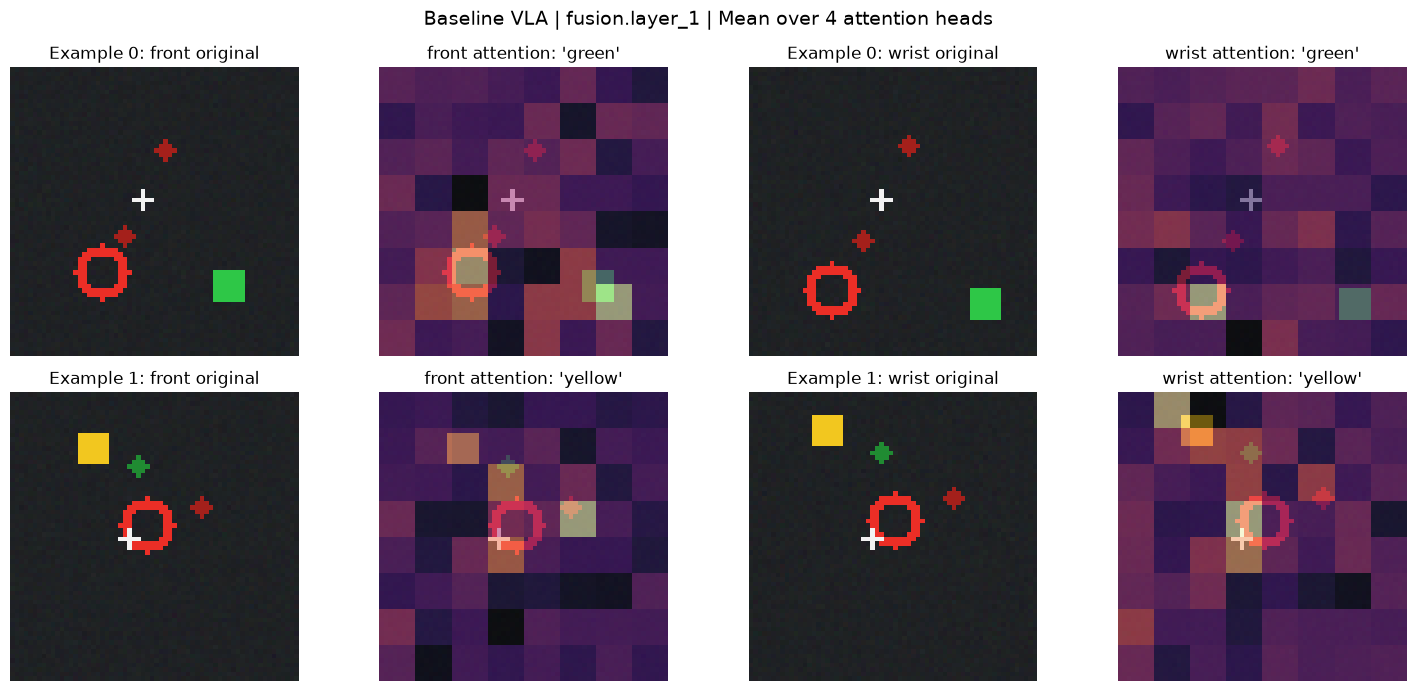

In [24]:
from pathlib import Path

import matplotlib.pyplot as plt
import torch
import torch.nn.functional as F

analysis_model.eval()
layer, token_idx, indices, cameras = "fusion.layer_1", 3, [0, 1], ["front", "wrist"]
vocab = datasets["validation"].vocabulary if "datasets" in globals() else None

with torch.no_grad():
    output = analysis_model(
        images=batch["images"],
        image_masks=batch["image_masks"],
        input_ids=batch["input_ids"],
        attention_mask=batch["attention_mask"],
        state=batch["state"],
        return_attentions=True,
        sample_seed=7,
    )

fig, axes = plt.subplots(len(indices), 4, figsize=(15, 7), squeeze=False)

for row, idx in enumerate(indices):
    token_id = int(batch["input_ids"][idx, token_idx])
    token = vocab.id_to_token[token_id] if vocab else f"token ID {token_id}"

    for j, camera in enumerate(cameras):
        img = batch["images"][camera][idx]
        img_np = img.permute(1, 2, 0).cpu().numpy()
        attn = language_to_image_attention(
            analysis_model,
            output.attentions,
            layer=layer,
            language_token_index=token_idx,
            camera_name=camera,
        )
        heat = attention_heatmap(analysis_model, attn)[idx]
        overlay = (
            F.interpolate(heat[None, None], size=img.shape[-2:], mode="nearest")[0, 0].cpu().numpy()
        )

        axes[row, 2 * j].imshow(img_np)
        axes[row, 2 * j].set_title(f"Example {idx}: {camera} original")
        axes[row, 2 * j + 1].imshow(img_np)
        axes[row, 2 * j + 1].imshow(overlay, cmap="magma", alpha=0.55)
        axes[row, 2 * j + 1].set_title(f"{camera} attention: '{token}'")

    for ax in axes[row]:
        ax.axis("off")

fig.suptitle(f"Baseline VLA | {layer} | Mean over 4 attention heads", fontsize=14)
plt.tight_layout()

out = RESULTS / "interpretability"
out.mkdir(parents=True, exist_ok=True)
plt.savefig(out / "attention_two_examples.png", dpi=200, bbox_inches="tight")
plt.show()

### 3.1 Top-attention vs. random-patch masking

For each camera, mask the **top 15% of patches** using the attention map and compare with **20 independently sampled random patch masks** of the same fraction. Keep the other camera, text, and state fixed; use the **same sampling seed (7)** for the reference and perturbed flow predictions. Report the mean action-change magnitude for both strategies and both examples. Attention scores alone cannot prove image reliance or causal relevance.

In [25]:
from pathlib import Path

import pandas as pd
import torch

from ml_project.interpretability import (
    action_change,
    attention_heatmap,
    language_to_image_attention,
    mask_top_attention_patches,
)

analysis_model.eval()
layer_name, token_index, fraction, seed, random_trials = "fusion.layer_1", 3, 0.15, 7, 20


def predict_actions(images):
    with torch.no_grad():
        return analysis_model(
            images=images,
            image_masks=batch["image_masks"],
            input_ids=batch["input_ids"],
            attention_mask=batch["attention_mask"],
            state=batch["state"],
            sample_seed=seed,
        ).actions


with torch.no_grad():
    ref = analysis_model(
        images=batch["images"],
        image_masks=batch["image_masks"],
        input_ids=batch["input_ids"],
        attention_mask=batch["attention_mask"],
        state=batch["state"],
        return_attentions=True,
        sample_seed=seed,
    )

results = []
for camera in ("front", "wrist"):
    attn = language_to_image_attention(
        analysis_model,
        ref.attentions,
        layer=layer_name,
        language_token_index=token_index,
        camera_name=camera,
    )
    heatmaps = attention_heatmap(analysis_model, attn)

    def masked_change(hm, camera=camera):
        images = dict(batch["images"])
        images[camera] = mask_top_attention_patches(images[camera], hm, fraction=fraction)
        return action_change(ref.actions, predict_actions(images)).cpu().numpy()

    attention_changes = masked_change(heatmaps)
    rng = np.random.default_rng(seed)
    random_changes = np.stack(
        [
            masked_change(torch.from_numpy(rng.random(tuple(heatmaps.shape))).to(heatmaps))
            for _ in range(random_trials)
        ]
    )

    for i, change in enumerate(attention_changes):
        results.append(
            dict(
                camera=camera,
                example=i,
                attention_mask_change=float(change),
                random_mask_change_mean=float(random_changes[:, i].mean()),
                random_mask_change_std=float(random_changes[:, i].std()),
            )
        )

perturbation_df = pd.DataFrame(results)
display(perturbation_df)
print("\nCamera-level means:")
display(
    perturbation_df.groupby("camera")[["attention_mask_change", "random_mask_change_mean"]].mean()
)

output_dir = RESULTS / "interpretability"
output_dir.mkdir(parents=True, exist_ok=True)
perturbation_df.to_csv(output_dir / "perturbation_results.csv", index=False)

,camera,example,attention_mask_change,random_mask_change_mean,random_mask_change_std
0,front,0,0.029684,0.044004,0.008998
1,front,1,0.040497,0.039117,0.005926
2,front,2,0.034857,0.031323,0.004542
3,front,3,0.045611,0.035823,0.004938
4,wrist,0,0.032402,0.041026,0.004990
5,wrist,1,0.029242,0.043489,0.005442
6,wrist,2,0.045150,0.042009,0.006157
7,wrist,3,0.041073,0.040994,0.004974



Camera-level means:


,attention_mask_change,random_mask_change_mean
camera,,
front,0.037662,0.037567
wrist,0.036967,0.041879


## 4. Supplementary: robustness and modality-dependence ablations

Perturbation tests were performed with fixed checkpoints and no retraining. Missing-camera and brightness tests assess numerical robustness. Shuffling images, language, or state tests **functional dependence**, not semantic understanding. In a stochastic flow model, clean/perturbed comparisons should share initial sampling noise.

,model,condition,validation_mse,change_vs_clean_pct
4,baseline,bright,0.03222,-0.04157
0,baseline,clean,0.03223,0.00000
3,baseline,dark,0.03656,13.43003
2,baseline,no_front,0.03664,13.68982
1,baseline,no_wrist,0.03753,16.44967
19,cross_full,bright,0.02191,0.03937
15,cross_full,clean,0.02190,0.00000
18,cross_full,dark,0.02213,1.02687
17,cross_full,no_front,0.02189,-0.03794
16,cross_full,no_wrist,0.02235,2.06256


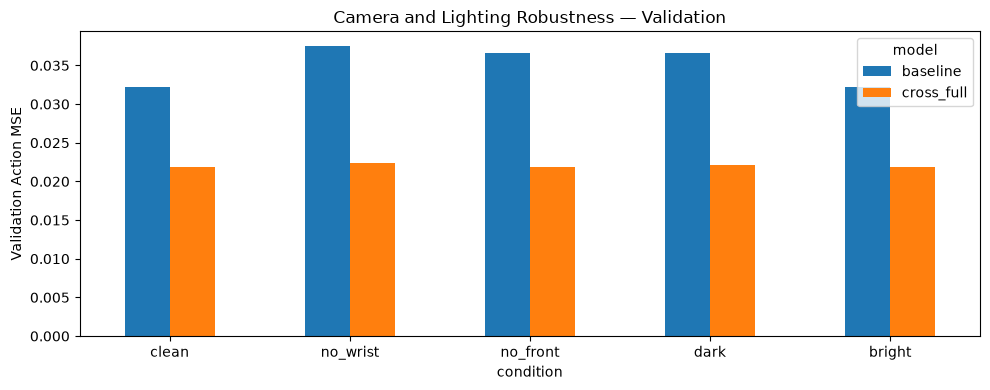

In [26]:
robustness_raw = csv_result("robustness_analysis/summary.csv")
conditions = ["clean", "no_wrist", "no_front", "dark", "bright"]

r = (
    robustness_raw.loc[
        robustness_raw["split"].eq("validation")
        & robustness_raw["model"].isin(["baseline", "cross_full"])
        & robustness_raw["condition"].isin(conditions)
    ]
    .copy()
    .rename(columns={"mse": "validation_mse"})
)

if r.empty or r.duplicated(["model", "condition"]).any():
    raise ValueError("Missing or duplicate validation rows. Check experiment results.")

clean = r.loc[r.condition.eq("clean")].set_index("model")["validation_mse"]
if not set(r.model).issubset(clean.index):
    raise ValueError("Missing clean reference for one or more models.")

r["change_vs_clean_pct"] = 100 * (r.validation_mse / r.model.map(clean) - 1)
display(
    r[["model", "condition", "validation_mse", "change_vs_clean_pct"]]
    .sort_values(["model", "condition"])
    .round(5)
)

ax = (
    r.pivot(index="condition", columns="model", values="validation_mse")
    .reindex(conditions)
    .plot.bar(figsize=(10, 4), rot=0)
)
ax.set(ylabel="Validation Action MSE", title="Camera and Lighting Robustness — Validation")
plt.tight_layout()
plt.show()

,model,clean,shuffle_images_pct,shuffle_language_pct,shuffle_both_pct
2,baseline,0.03223,0.03226,0.01663,0.04870
5,cross_full,0.02190,0.06195,0.00158,0.06552


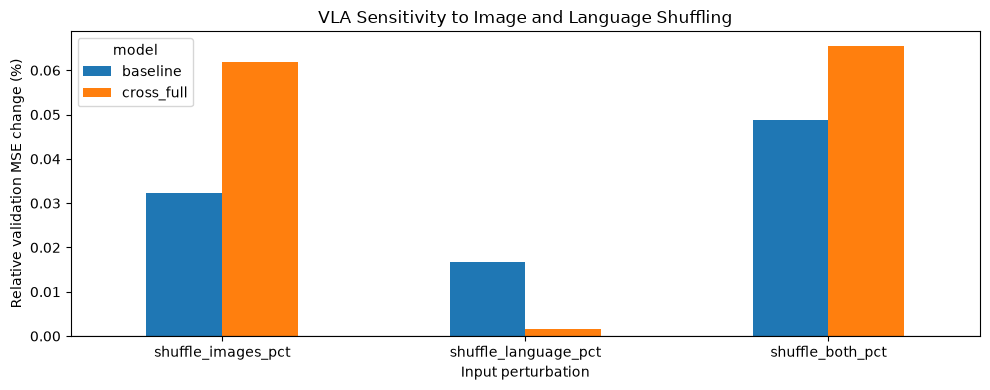

Maximum absolute relative MSE change: 0.0655%
Both models show less than 0.1% change.


In [27]:
modality = csv_result("modality_diagnostics/modality_effects.csv")
modality = modality[
    modality["split"].eq("validation") & modality["model"].isin(["baseline", "cross_full"])
].copy()
modality = modality.rename(
    columns={
        "shuffle_images_relative_mse_change_pct": "shuffle_images_pct",
        "shuffle_language_relative_mse_change_pct": "shuffle_language_pct",
        "shuffle_both_relative_mse_change_pct": "shuffle_both_pct",
    }
)
cols = ["shuffle_images_pct", "shuffle_language_pct", "shuffle_both_pct"]

display(modality[["model", "clean"] + cols].round(5))

ax = modality.set_index("model")[cols].T.plot.bar(figsize=(10, 4), rot=0)
ax.set(
    xlabel="Input perturbation",
    ylabel="Relative validation MSE change (%)",
    title="VLA Sensitivity to Image and Language Shuffling",
)
ax.axhline(0, color="black", lw=0.8)
plt.tight_layout()
plt.show()

max_change = modality[cols].abs().max().max()
print(f"Maximum absolute relative MSE change: {max_change:.4f}%")
print(
    "Both models show less than 0.1% change."
    if max_change < 0.1
    else "At least one perturbation changes validation MSE by 0.1% or more."
)

**Finding:** On validation, shuffling images, language, or state changes aggregate MSE by less than 0.1% for either model. This suggests an input-independent action prior or weak learned conditioning, but **aggregate MSE insensitivity alone does not prove identical predictions**. Verify prediction-level changes and that perturbations reach the model. Do not claim improved visual grounding from the cross-attention architecture.

## 5. Supplementary: action-space decomposition and deployment caveat

Dimension 6 has a **mean of +0.375** in train/validation/week 1 (`robot_01`) and **−0.375** in week 2 (`robot_03`). Robot identity and deployment week are confounded. The sign change is an observed **robot-associated label shift**, not verified evidence of a physical control convention. Report motion-channel MSE (dimensions 0–5) separately from dimension-6 MSE.

,split,robot_id,n,dim6_mean,dim6_std
0,deployment_week_1,robot_01,29,0.375,0.0
1,deployment_week_2,robot_03,33,-0.375,0.0
2,train,robot_01,512,0.375,0.0
3,validation,robot_01,128,0.375,0.0


model,baseline,cross_full
dimension,,
0,0.044105,0.039970
1,0.044550,0.031632
2,0.012660,0.013860
3,0.014510,0.009219
4,0.011588,0.008927
5,0.009997,0.008332
6,2.152460,2.678909


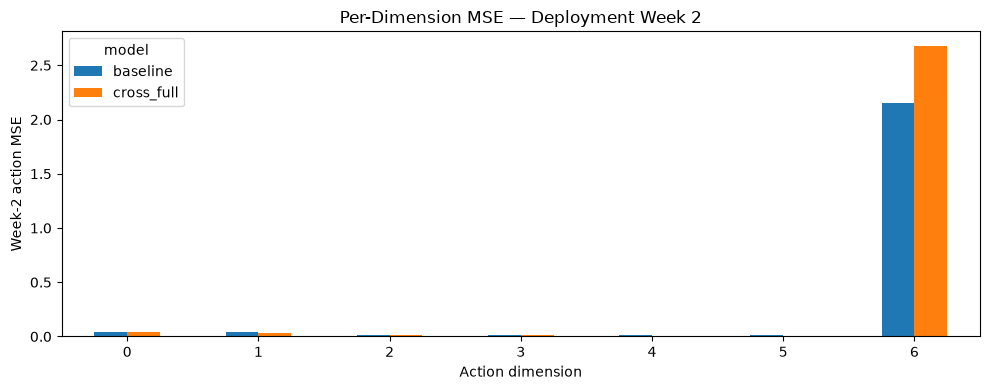

baseline: overall=0.327124, motion=0.022902, dim6=2.152460, dim6 contribution=94.00%
cross_full: overall=0.398693, motion=0.018657, dim6=2.678909, dim6 contribution=95.99%


In [28]:
# Robot-specific dimension-6 statistics
dim6 = csv_result("state_dependency/dim6_by_robot.csv")
display(dim6[["split", "robot_id", "n", "dim6_mean", "dim6_std"]].sort_values("split").round(6))

# Week-2 per-dimension MSE
p = csv_result("robustness_analysis/per_dimension.csv")
p = p[
    p["split"].eq("deployment_week_2")
    & p["condition"].eq("clean")
    & p["model"].isin(["baseline", "cross_full"])
]
if p.empty:
    raise ValueError("No clean week-2 results found.")

per_dim_week2 = p.groupby(["dimension", "model"], as_index=False).agg(
    mse=("mse", "mean"), n_samples=("sample_id", "nunique")
)
pivot = per_dim_week2.pivot(index="dimension", columns="model", values="mse").sort_index()
display(pivot.round(6))

# Plot
ax = pivot.plot.bar(figsize=(10, 4), rot=0, title="Per-Dimension MSE — Deployment Week 2")
ax.set(xlabel="Action dimension", ylabel="Week-2 action MSE")
plt.tight_layout()
plt.show()

# Dimension-6 contribution
for model in pivot.columns:
    e = pivot[model]
    print(
        f"{model}: overall={e.mean():.6f}, motion={e.loc[0:5].mean():.6f}, "
        f"dim6={e.loc[6]:.6f}, dim6 contribution={100 * e.loc[6] / e.sum():.2f}%"
    )

## 6. Supplementary: statistical controls and direct regression

Statistical baselines are fitted **only on training labels**. The mean-action predictor uses no observations, task means use training task labels, and ridge regression uses only the 7D state. Direct regression replaces iterative flow generation with a deterministic action head. The 200-step regression models are not an exact objective-only ablation unless architecture and training settings are otherwise matched.

,model,validation_mse,week1_mse,week2_mse
5,state_ridge,0.004089,0.004478,0.362254
3,State-only MLP (200 steps),0.004711,0.005046,0.361717
4,global_mean,0.004931,0.005026,0.362728
6,task_mean,0.005009,0.005177,0.362478
2,Cross-attention regression VLA (200 steps),0.005870,0.005931,0.370757
1,Cross-attention flow VLA (200 steps),0.021902,0.020923,0.398693
0,Original TinyVLA flow,0.032230,0.031059,0.327124


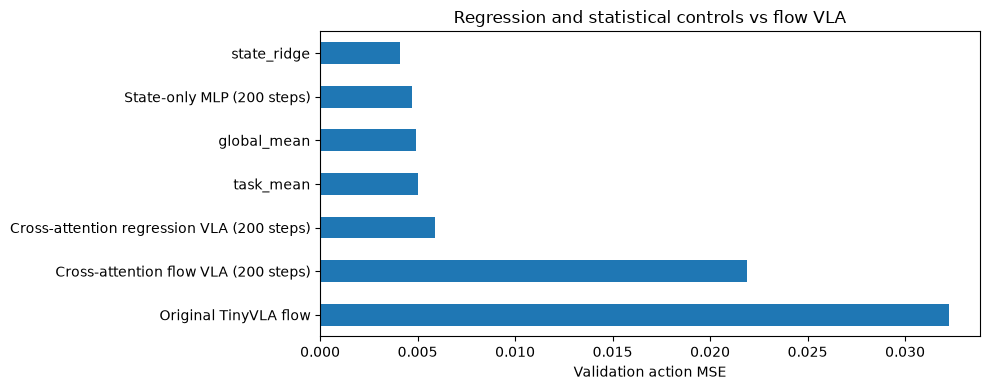

In [29]:
models = {
    "Original TinyVLA flow": "baseline/metrics.json",
    "Cross-attention flow VLA (200 steps)": "cross_full/metrics.json",
    "Cross-attention regression VLA (200 steps)": "regression_200/regression_vla/metrics.json",
    "State-only MLP (200 steps)": "regression_200/state_mlp/metrics.json",
}
rows = []
for name, file in models.items():
    d = json_result(file)
    rows.append(
        {
            "model": name,
            **{
                out: (
                    float(d[section]["mse"])
                    if isinstance(d.get(section), dict)
                    and isinstance(d[section].get("mse"), (int, float))
                    else np.nan
                )
                for out, section in [
                    ("validation_mse", "validation"),
                    ("week1_mse", "deployment_week_1"),
                    ("week2_mse", "deployment_week_2"),
                ]
            },
        }
    )
comparison = pd.DataFrame(rows)
# Flow experiment metrics contain validation only;
# use independently saved clean deployment evaluations.
# saved clean deployment evaluations.
robust_eval = csv_result("robustness_analysis/summary.csv")
for display_name, key in [
    ("Original TinyVLA flow", "baseline"),
    ("Cross-attention flow VLA (200 steps)", "cross_full"),
]:
    for split, target_col in [
        ("deployment_week_1", "week1_mse"),
        ("deployment_week_2", "week2_mse"),
    ]:
        hit = robust_eval.loc[
            (robust_eval["model"] == key)
            & (robust_eval["split"] == split)
            & (robust_eval["condition"] == "clean"),
            "mse",
        ]
        if len(hit) == 1:
            comparison.loc[comparison.model.eq(display_name), target_col] = float(hit.iloc[0])
simple_raw = csv_result("simple_baselines/summary.csv")
s = simple_raw.copy().rename(
    columns={
        col(simple_raw, "model", "model_name"): "model",
        col(simple_raw, "split", "dataset", "window"): "split",
        col(simple_raw, "mse", "action_mse"): "mse",
    }
)
s = s[s.model.isin(["state_ridge", "global_mean", "task_mean"])].copy()
s["split"] = s["split"].replace({"week1": "deployment_week_1", "week2": "deployment_week_2"})
wide = (
    s.pivot_table(index="model", columns="split", values="mse", aggfunc="first")
    .rename(
        columns={
            "validation": "validation_mse",
            "deployment_week_1": "week1_mse",
            "deployment_week_2": "week2_mse",
        }
    )
    .reset_index()
)
comparison = pd.concat([comparison, wide], ignore_index=True)
comparison = comparison.reindex(columns=["model", "validation_mse", "week1_mse", "week2_mse"])
display(comparison.sort_values("validation_mse").round(6))
d = comparison.dropna(subset=["validation_mse"]).sort_values("validation_mse")
ax = d.plot.barh(x="model", y="validation_mse", figsize=(10, 4), legend=False)
ax.invert_yaxis()
ax.set(
    xlabel="Validation action MSE",
    ylabel="",
    title="Regression and statistical controls vs flow VLA",
)
plt.tight_layout()
plt.show()

**Interpretation.** Direct regression VLA reduces validation MSE by approximately **73.2%** relative to the cross-attention flow model. State-only ridge reaches **0.004089**, and even the unconditional global mean achieves **0.004931**. Thus the benchmark has a strong action-prior shortcut; model complexity is not justified by aggregate MSE alone. Week-2 overall MSE is dominated by a robot-associated dimension-6 shift, so it should not be treated as evidence of visual domain-shift failure.

## 7. Reproduction and evidence locations

From the repository root, use the scripts associated with the saved runs. These commands are documented for reproduction and **do not execute automatically** in the notebook:

```powershell
python .\scripts\compare_metrics.py
uv run python scripts/evaluate_robustness.py --device cpu --cross-checkpoint results/cross_full/model.pt --baseline-checkpoint checkpoints/baseline.pt
uv run python scripts/evaluate_modality_diagnostics.py --device cpu --cross-checkpoint results/cross_full/model.pt --baseline-checkpoint checkpoints/baseline.pt
uv run python scripts/evaluate_simple_baselines.py --output-dir results/simple_baselines
uv run python scripts/run_regression_comparison.py --steps 200 --model both --device cpu --output-dir results/regression_200
```

Existing result folders include `results/robustness_analysis/`, `results/modality_diagnostics/`, `results/simple_baselines/`, and `results/regression_200/`. Verify exact checkpoint names and script availability in the local repository.

## 8. Conclusions and next actions

1. **Architecture:** Action-query decoding plus language-guided cross-attention produced the best **flow-based** validation MSE (0.021902), but did not establish visual grounding.
2. **Decoder/objective:** Deterministic regression VLA performed much better (0.005870), suggesting iterative generative decoding/optimization is inefficient for this benchmark.
3. **Data shortcut:** Global mean (0.004931) and state-only ridge (0.004089) outperform the learned VLAs; therefore include these as mandatory controls.
4. **Deployment:** Week-2 action dimension 6 changes with robot identity. Verify the schema/adapter and test safely before considering any sign correction; do not fit corrections using deployment labels.
5. **Uncertainty:** Deployment label counts are small (29/33), and most architecture results are single-seed. Report uncertainty and selection bias; avoid claiming robot readiness from offline metrics.

**Recommended follow-up:** Check prediction-level modality sensitivity with matched flow noise; inspect action schemas; repeat top configurations over multiple seeds and equal training budgets. If time allows, test residual direct regression initialized around the training action mean.